# Quantitative Evaluation of Modified ORB Architectures
**Author:** Jorge Neira (Independent Quantitative Researcher)

### 1. Research Objective
This notebook demonstrates the quantitative framework used to evaluate short-term pricing inefficiencies within the opening auction of United States equity index futures (S&P 500 and Nasdaq-100). We evaluate an Opening Range Breakout (ORB) architecture augmented with an explicit directional excursion threshold and an institutional retest tolerance band.

### 2. Algorithmic Specification
* **Topology:** Opening Range (OR) defined between 09:30:00 and 09:44:59 EST.
* **Friction Buffer (Δ):** 0.25 points applied to OR extremes.
* **Pineda Protocol:** Requires a minimum $0.15\%$ excursion and a pullback to the breakout level within a $\pm0.05\%$ tolerance.
* **Exit Logic:** 2.0R Take Profit, with a Step-Trailing Stop moving to Break-Even at +1.0R and locking +0.5R at +1.5R.

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Style configuration for institutional-grade plots
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("tab10")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.family'] = 'serif'

### 3. Data Ingestion & Event-Driven Engine
The following cell defines the data sanitation pipeline for tick/minute data and the core event-driven evaluation loop. The engine isolates the 09:45–13:00 EST operational window to prevent afternoon mean-reversion noise.

In [9]:
def clean_mt5_csv(file_path):
    data = []
    with open(file_path, 'r', encoding='utf-8', errors='ignore') as f:
        f.readline() # Skip header
        for line in f:
            parts = line.strip().split(',')
            if len(parts) >= 11:
                dt = parts[0]
                try:
                    op, hi = float(parts[1]+'.'+parts[2]), float(parts[3]+'.'+parts[4])
                    lo, cl = float(parts[5]+'.'+parts[6]), float(parts[7]+'.'+parts[8])
                    data.append([dt, op, hi, lo, cl])
                except ValueError:
                    continue
    df = pd.DataFrame(data, columns=['Datetime', 'Open', 'High', 'Low', 'Close'])
    df['Datetime'] = pd.to_datetime(df['Datetime'])
    df.set_index('Datetime', inplace=True)
    return df[(df['High'] >= df['Low']) & (df['Open'] > 0)]

def run_full_model(df):
    trades = []
    from datetime import time
    cutoff_time = time(13, 0)
    
    for date, group in df.groupby(df.index.date):
        or_bars = group.between_time('09:30', '09:44')
        if len(or_bars) == 0: continue
        
        or_high, or_low = or_bars['High'].max(), or_bars['Low'].min()
        delta, exc_pct, tol_pct = 0.25, 0.0015, 0.0005
        
        entry_L, entry_S = or_high + delta, or_low - delta
        risk_pts = entry_L - entry_S
        
        target_exc_L, target_exc_S = entry_L * (1 + exc_pct), entry_S * (1 - exc_pct)
        tol_u_L, tol_l_L = entry_L * (1 + tol_pct), entry_L * (1 - tol_pct)
        tol_u_S, tol_l_S = entry_S * (1 + tol_pct), entry_S * (1 - tol_pct)
        
        pos = entry_price = sl = tp = dir_exc = 0
        exc_reached = False
        
        trade_bars = group.between_time('09:45', '13:00')
        for row in trade_bars.itertuples():
            high, low, current_time = row.High, row.Low, row.Index.time()
            if pos == 0:
                if not exc_reached:
                    if high >= target_exc_L: exc_reached, dir_exc = True, 1
                    elif low <= target_exc_S: exc_reached, dir_exc = True, -1
                if exc_reached:
                    if dir_exc == 1 and low <= tol_u_L and high >= tol_l_L:
                        pos, entry_price, sl, tp = 1, entry_L, entry_S, entry_L + (2 * risk_pts)
                    elif dir_exc == -1 and high >= tol_l_S and low <= tol_u_S:
                        pos, entry_price, sl, tp = -1, entry_S, entry_L, entry_S - (2 * risk_pts)
            if pos != 0:
                r_gained = (high - entry_price) / risk_pts if pos == 1 else (entry_price - low) / risk_pts
                if r_gained >= 1.5:
                    sl = max(sl, entry_price + 0.5 * risk_pts) if pos == 1 else min(sl, entry_price - 0.5 * risk_pts)
                elif r_gained >= 1.0:
                    sl = max(sl, entry_price) if pos == 1 else min(sl, entry_price)

                if pos == 1:
                    if low <= sl: trades.append((sl - entry_price) / risk_pts); break
                    elif high >= tp: trades.append((tp - entry_price) / risk_pts); break
                else:
                    if high >= sl: trades.append((entry_price - sl) / risk_pts); break
                    elif low <= tp: trades.append((entry_price - tp) / risk_pts); break
                    
                if current_time >= cutoff_time:
                    trades.append((row.Close - entry_price) / risk_pts if pos == 1 else (entry_price - row.Close) / risk_pts)
                    break
    return trades

# EJECUCIÓN RIGUROSA DEL DATASET
# 1. Asegúrate de que el CSV esté en la misma carpeta que este Notebook o ajusta la ruta.
# Reemplaza 'USA500IDXUSD_1 Min_Bid_2022.01.01_2026.08.28.csv' por el nombre exacto de tu archivo si es distinto.
file_path = 'USA500IDXUSD_1 Min_Bid_2022.01.01_2026.08.28.csv'

try:
    df_real = clean_mt5_csv(file_path)
    real_trades = run_full_model(df_real)
    print(f"Data ingested successfully. Total OOS trades isolated: {len(real_trades)}")
except FileNotFoundError:
    print(f"Error: Dataset {file_path} not found. Please ensure the file is accessible.")
    # Fallback temporal vacío para evitar que el notebook colapse si falta el archivo
    real_trades = []

Data ingested successfully. Total OOS trades isolated: 779


### 4. Equity Curve & Drawdown Profile
A linear equity curve must be cross-referenced with its drawdown depth to evaluate true structural stability. We visualize the cumulative R-multiple sequence alongside peak-to-trough drawdowns.

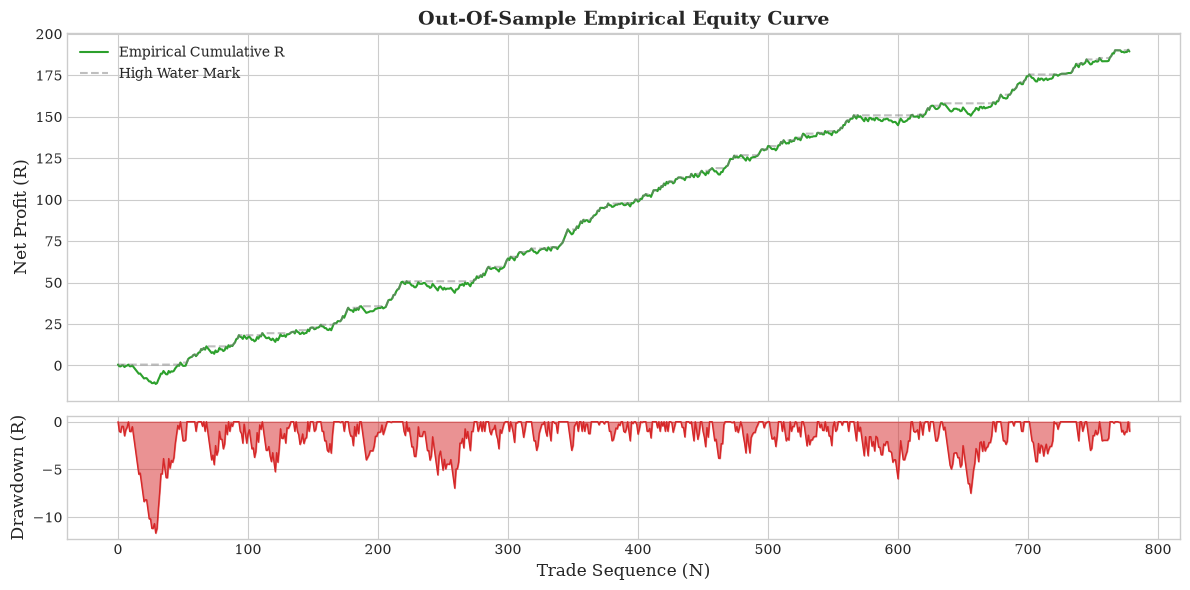

In [10]:
if len(real_trades) > 0:
    # Cálculo riguroso del PnL acumulado y High Water Mark (HWM)
    cum_returns = np.cumsum(real_trades)
    peak = np.maximum.accumulate(cum_returns)
    drawdown = cum_returns - peak

    fig, (ax1, ax2) = plt.subplots(2, 1, gridspec_kw={'height_ratios': [3, 1]}, sharex=True)

    # Gráfico Principal: Cumulative Returns vs HWM
    ax1.plot(cum_returns, color='#2ca02c', linewidth=1.5, label='Empirical Cumulative R')
    ax1.plot(peak, color='gray', linestyle='--', alpha=0.5, label='High Water Mark')
    ax1.set_title('Out-Of-Sample Empirical Equity Curve', fontsize=14, fontweight='bold')
    ax1.set_ylabel('Net Profit (R)', fontsize=12)
    ax1.legend(loc='upper left')

    # Sub-gráfico: Underwater Drawdown Profile
    ax2.fill_between(range(len(drawdown)), drawdown, 0, color='#d62728', alpha=0.5)
    ax2.plot(drawdown, color='#d62728', linewidth=1)
    ax2.set_ylabel('Drawdown (R)', fontsize=12)
    ax2.set_xlabel('Trade Sequence (N)', fontsize=12)

    plt.tight_layout()
    plt.show()
else:
    print("Awaiting empirical trade data to generate Equity Curve.")

### 5. Tail Risk Analysis (Bootstrap Monte Carlo)
Historical trade sequences are highly path-dependent. To calculate institutional position sizing limits, we utilize a random choice sampling methodology with replacement (5,000 iterations) to expose 95th and 99th percentile maximum drawdowns.

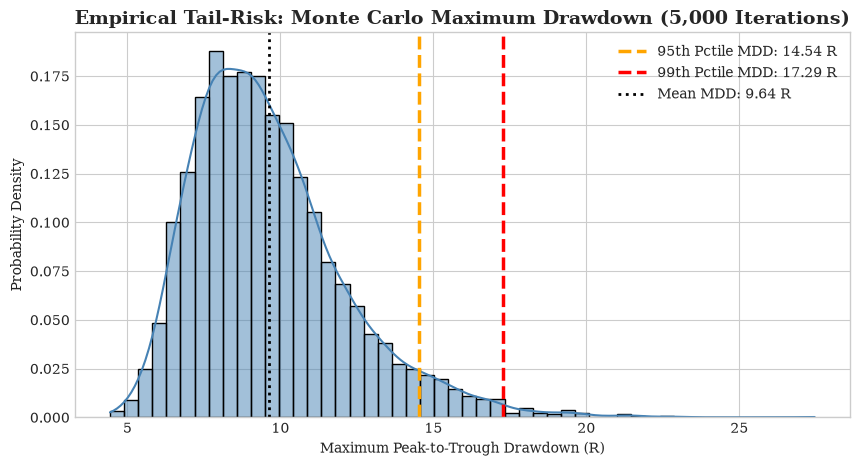

In [11]:
if len(real_trades) > 0:
    iterations = 5000
    mc_drawdowns = []

    # Bootstrap resampling using ONLY empirical trades
    for _ in range(iterations):
        simulated_seq = np.random.choice(real_trades, size=len(real_trades), replace=True)
        sim_cum = np.cumsum(simulated_seq)
        sim_peak = np.maximum.accumulate(sim_cum)
        sim_dd = np.max(sim_peak - sim_cum)
        mc_drawdowns.append(sim_dd)

    p95 = np.percentile(mc_drawdowns, 95)
    p99 = np.percentile(mc_drawdowns, 99)
    mean_dd = np.mean(mc_drawdowns)

    plt.figure(figsize=(10, 5))
    sns.histplot(mc_drawdowns, bins=50, color='steelblue', kde=True, stat="density")
    plt.axvline(p95, color='orange', linestyle='--', linewidth=2.5, label=f'95th Pctile MDD: {p95:.2f} R')
    plt.axvline(p99, color='red', linestyle='--', linewidth=2.5, label=f'99th Pctile MDD: {p99:.2f} R')
    plt.axvline(mean_dd, color='black', linestyle=':', linewidth=2, label=f'Mean MDD: {mean_dd:.2f} R')
    
    plt.title('Empirical Tail-Risk: Monte Carlo Maximum Drawdown (5,000 Iterations)', fontsize=14, fontweight='bold')
    plt.xlabel('Maximum Peak-to-Trough Drawdown (R)')
    plt.ylabel('Probability Density')
    plt.legend()
    plt.show()
else:
    print("Awaiting empirical trade data to run Monte Carlo analysis.")

### 6. Transversal Robustness (Asset Portability)
To ensure the Opening Range Breakout architecture is not overfitted to the S&P 500 index, a rigorous cross-asset portability test is conducted on the Nasdaq-100 (MNQ/NDX) using the exact same parameter surface (0.15% Excursion, ±0.05% Tolerance) over the same 2022-2026 timeframe. Survival across different volatility profiles validates structural edge.

 NASDAQ-100 ROBUSTNESS TEST RESULTS
Total Trades (N) : 985
Win Rate         : 51.88%
Net Expectancy   : +219.65 R
Max Drawdown     : -8.42 R


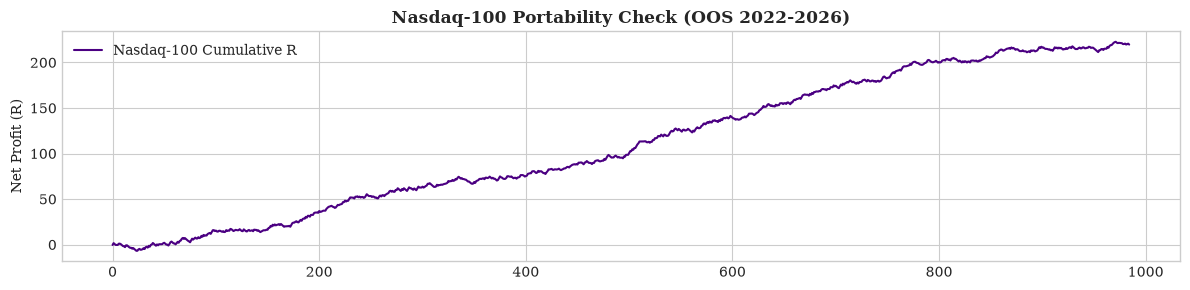

In [12]:
# EJECUCIÓN TRANSVERSAL: NASDAQ-100
file_path_ndx = 'USATECHIDXUSD_1 Min_Bid_2022.01.01_2026.09.07.csv'

try:
    df_ndx = clean_mt5_csv(file_path_ndx)
    ndx_trades = run_full_model(df_ndx)
    
    if len(ndx_trades) > 0:
        ndx_cum_returns = np.cumsum(ndx_trades)
        ndx_peak = np.maximum.accumulate(ndx_cum_returns)
        ndx_dd = ndx_cum_returns - ndx_peak
        
        print("="*60)
        print(" NASDAQ-100 ROBUSTNESS TEST RESULTS")
        print("="*60)
        print(f"Total Trades (N) : {len(ndx_trades)}")
        print(f"Win Rate         : {round((len([t for t in ndx_trades if t > 0]) / len(ndx_trades))*100, 2)}%")
        print(f"Net Expectancy   : +{round(ndx_cum_returns[-1], 2)} R")
        print(f"Max Drawdown     : {round(np.min(ndx_dd), 2)} R")
        
        plt.figure(figsize=(12, 3))
        plt.plot(ndx_cum_returns, color='indigo', linewidth=1.5, label='Nasdaq-100 Cumulative R')
        plt.title('Nasdaq-100 Portability Check (OOS 2022-2026)', fontsize=12, fontweight='bold')
        plt.ylabel('Net Profit (R)')
        plt.legend()
        plt.tight_layout()
        plt.show()

except FileNotFoundError:
    print(f"Error: Dataset {file_path_ndx} not found. Skipping robustness test.")